# Gold (XAU/USD) market behaviour analysis

I trade gold and wanted to check some things I usually just assume: when in the day gold actually moves, whether the London breakout is real, how much news days matter, whether gold still follows the dollar and real yields, and whether next-day volatility can be predicted.

**Data:** daily gold futures (GC=F) since 2010, ~2 years of hourly gold, DXY, VIX, US 10Y yield (Yahoo Finance), 10Y real yield (US Treasury), and FOMC / CPI / NFP dates (Fed and BLS websites). Everything goes into a SQLite database; most of the analysis is SQL, then Python for statistics and ML.

**Approach:** every claim is tested against an explicit benchmark (a null model, a naive baseline or the previous period), reported with a confidence interval rather than a point estimate, and every model is validated walk-forward so it never sees the future.

| Section | Question | Method |
|---|---|---|
| 1 | When does gold move? | SQL window functions, random-walk null model (Monte Carlo), chi-square test |
| 2 | Does the London breakout work? | SQL backtest view, realistic fills, drift adjustment, bootstrap CIs |
| 3 | How much do FOMC / CPI / NFP move gold? | Event study, Mann-Whitney with Holm correction, bootstrap CIs |
| 4 | Does gold still follow the dollar and real yields? | Correlation of changes at several horizons, HAC regression, Fisher z-test |
| 5 | Which days were abnormal? | Isolation Forest with stability and driver analysis |
| 6 | Can tomorrow's volatility be predicted? | Logistic regression vs XGBoost vs HAR vs naive, walk-forward CV, block-bootstrap AUC, calibration |

*Note:* I used gold futures instead of spot XAU/USD because free hourly spot history is hard to get. Futures track spot very closely, apart from a small carry and occasional contract-roll gaps (handled in Sections 0 and 5).

*Note on the "Findings" cells:* the written findings come from my last full run. Market data updates daily, so after **Run all** check the printed tables; anything marked ⟳ is a number that should be refreshed from the output.

In [1]:
!pip install -q -U yfinance

import os, io, time, sqlite3, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests

# Only silence pandas deprecation noise; real warnings (convergence, etc.) stay visible
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (11, 4.5)
pd.set_option("display.width", 160)
SEED = 42

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.3/149.3 kB 3.9 MB/s eta 0:00:00


## 0. Data

In [2]:
import yfinance as yf

os.makedirs("data", exist_ok=True)
START = "2010-01-01"

def get_yahoo(ticker, **kwargs):
    for attempt in range(4):
        df = yf.download(ticker, auto_adjust=False, progress=False, **kwargs)
        if len(df):
            df.columns = [c[0] if isinstance(c, tuple) else c for c in df.columns]
            return df
        time.sleep(10)
    raise RuntimeError(f"Yahoo download failed for {ticker}, try again in a minute")

def get_real_yield():
    # 10Y real yield from the Treasury's daily real yield curve (one CSV per year)
    frames = []
    for year in range(2010, pd.Timestamp.today().year + 1):
        url = ("https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
               f"daily-treasury-rates.csv/{year}/all?type=daily_treasury_real_yield_curve"
               f"&field_tdr_date_value={year}&page&_format=csv")
        r = requests.get(url, headers={"User-Agent": "Mozilla/5.0"}, timeout=90)
        r.raise_for_status()
        t = pd.read_csv(io.StringIO(r.text))
        frames.append(pd.DataFrame({"date": pd.to_datetime(t["Date"], format="%m/%d/%Y"), "real_yield": t["10 YR"]}))
    return pd.concat(frames).sort_values("date")

# Downloads are cached in data/ so a re-run analyses the same snapshot (delete the folder to refresh)
if not os.path.exists("data/gold_daily.csv"):
    get_yahoo("GC=F", start=START).to_csv("data/gold_daily.csv")
if not os.path.exists("data/gold_hourly.csv"):
    hourly_start = (pd.Timestamp.today() - pd.Timedelta(days=725)).strftime("%Y-%m-%d")  # Yahoo keeps ~730 days of hourly bars
    get_yahoo("GC=F", start=hourly_start, interval="1h").to_csv("data/gold_hourly.csv")
if not os.path.exists("data/macro_daily.csv"):
    macro = pd.concat({"dxy": get_yahoo("DX-Y.NYB", start=START)["Close"],
                       "vix": get_yahoo("^VIX", start=START)["Close"]}, axis=1)
    macro.index.name = "Date"
    macro.to_csv("data/macro_daily.csv")
if not os.path.exists("data/real_yield.csv"):
    get_real_yield().to_csv("data/real_yield.csv", index=False)

os.listdir("data")

['gold_daily.csv', 'gold_hourly.csv', 'real_yield.csv', 'macro_daily.csv']

In [3]:
gd = pd.read_csv("data/gold_daily.csv")
gd.columns = [c.lower().replace(" ", "_") for c in gd.columns]
gd["date"] = pd.to_datetime(gd["date"].astype(str).str[:10])
gd = gd.dropna(subset=["open", "high", "low", "close"])
print("stale daily bars (high == low):", (gd["high"] == gd["low"]).sum())
gd = gd[gd["high"] > gd["low"]]
# yahoo's close is the settlement price, which can sit slightly outside high/low
gd["high"] = gd[["high", "open", "close"]].max(axis=1)
gd["low"] = gd[["low", "open", "close"]].min(axis=1)
gd = gd.sort_values("date").drop_duplicates("date")[["date", "open", "high", "low", "close", "volume"]]

gh = pd.read_csv("data/gold_hourly.csv")
gh.columns = [c.lower().replace(" ", "_") for c in gh.columns]
gh["ts"] = pd.to_datetime(gh["datetime"], utc=True).dt.tz_convert("America/New_York")
gh = gh[gh["high"] > gh["low"]].dropna(subset=["open", "high", "low", "close"])
gh = gh.drop_duplicates("ts")
# CME gold trades 18:00-17:00 NY time, so a 19:00 Sunday bar belongs to Monday
gh["trading_date"] = (gh["ts"] + pd.Timedelta(hours=6)).dt.tz_localize(None).dt.normalize()
gh["hour"] = gh["ts"].dt.hour
gh["session"] = np.select([(gh["hour"] >= 18) | (gh["hour"] < 3), gh["hour"] < 8, gh["hour"] < 17],
                          ["Asia", "London", "New York"], "Closed")
gh = gh[gh["trading_date"].dt.dayofweek < 5].sort_values("ts").reset_index(drop=True)

macro = pd.read_csv("data/macro_daily.csv", parse_dates=["Date"]).rename(columns={"Date": "date"})
macro = macro[["date", "dxy", "vix"]]
ry = pd.read_csv("data/real_yield.csv", parse_dates=["date"]).dropna()

print(len(gd), "daily rows,", gd["date"].min().date(), "to", gd["date"].max().date())
print(len(gh), "hourly rows,", gh["trading_date"].min().date(), "to", gh["trading_date"].max().date())

stale daily bars (high == low): 149
4071 daily rows, 2010-01-04 to 2026-10-13
11350 hourly rows, 2024-10-18 to 2026-10-13


### Data-quality checks
Hard checks (`assert`) stop the notebook if the data is structurally broken. Soft checks are reported so I know what each later result is exposed to; the opening-gap count matters because GC=F is a continuous contract, so roll days can show price jumps that never happened in spot gold.

In [4]:
assert gd["date"].is_unique and gd["date"].is_monotonic_increasing
assert (gd["high"] >= gd[["open", "close"]].max(axis=1)).all()
assert (gd["low"] <= gd[["open", "close"]].min(axis=1)).all()
assert not gh["ts"].duplicated().any(), "duplicate hourly timestamps"
assert gh["session"].isin(["Asia", "London", "New York", "Closed"]).all()

bars_per_day = gh[gh["session"] != "Closed"].groupby("trading_date").size()
daily_ret = gd.set_index("date")["close"].pct_change()
open_gap = (gd["open"] / gd["close"].shift(1) - 1).abs()
pd.Series({
    "daily rows": len(gd),
    "calendar gaps > 4 days": int((gd["date"].diff().dt.days > 4).sum()),
    "daily moves > 5%": int((daily_ret.abs() > 0.05).sum()),
    "opening gaps > 2% (possible contract rolls)": int((open_gap > 0.02).sum()),
    "hourly trading days": len(bars_per_day),
    "hourly days with < 20 bars (dropped from intraday stats)": int((bars_per_day < 20).sum()),
    "macro days missing VIX": int(macro["vix"].isna().sum()),
    "macro days missing DXY": int(macro["dxy"].isna().sum()),
    "real-yield days": len(ry),
}).to_frame("value")

,value
daily rows,4071
calendar gaps > 4 days,24
daily moves > 5%,10
opening gaps > 2% (possible contract rolls),28
hourly trading days,509
hourly days with < 20 bars (dropped from intraday stats),31
macro days missing VIX,3
macro days missing DXY,4
real-yield days,4196


Event dates: FOMC decision days (plus the two emergency cuts in March 2020), and CPI / NFP release days from the BLS archives, including the ones delayed by the 2013 and 2025 shutdowns. Dates in the future are harmless (there is no price row to join to), and the check below lists any event date that lands on a day without a gold bar, which usually means a typo.

In [5]:
FOMC = """
2010-01-27 2010-03-16 2010-04-28 2010-06-23 2010-08-10 2010-09-21 2010-11-03 2010-12-14
2011-01-26 2011-03-15 2011-04-27 2011-06-22 2011-08-09 2011-09-21 2011-11-02 2011-12-13
2012-01-25 2012-03-13 2012-04-25 2012-06-20 2012-08-01 2012-09-13 2012-10-24 2012-12-12
2013-01-30 2013-03-20 2013-05-01 2013-06-19 2013-07-31 2013-09-18 2013-10-30 2013-12-18
2014-01-29 2014-03-19 2014-04-30 2014-06-18 2014-07-30 2014-09-17 2014-10-29 2014-12-17
2015-01-28 2015-03-18 2015-04-29 2015-06-17 2015-07-29 2015-09-17 2015-10-28 2015-12-16
2016-01-27 2016-03-16 2016-04-27 2016-06-15 2016-07-27 2016-09-21 2016-11-02 2016-12-14
2017-02-01 2017-03-15 2017-05-03 2017-06-14 2017-07-26 2017-09-20 2017-11-01 2017-12-13
2018-01-31 2018-03-21 2018-05-02 2018-06-13 2018-08-01 2018-09-26 2018-11-08 2018-12-19
2019-01-30 2019-03-20 2019-05-01 2019-06-19 2019-07-31 2019-09-18 2019-10-30 2019-12-11
2020-01-29 2020-03-03 2020-03-16 2020-04-29 2020-06-10 2020-07-29 2020-09-16 2020-11-05 2020-12-16
2021-01-27 2021-03-17 2021-04-28 2021-06-16 2021-07-28 2021-09-22 2021-11-03 2021-12-15
2022-01-26 2022-03-16 2022-05-04 2022-06-15 2022-07-27 2022-09-21 2022-11-02 2022-12-14
2023-02-01 2023-03-22 2023-05-03 2023-06-14 2023-07-26 2023-09-20 2023-11-01 2023-12-13
2024-01-31 2024-03-20 2024-05-01 2024-06-12 2024-07-31 2024-09-18 2024-11-07 2024-12-18
2025-01-29 2025-03-19 2025-05-07 2025-06-18 2025-07-30 2025-09-17 2025-10-29 2025-12-10
2026-01-28 2026-03-18 2026-04-29 2026-06-17 2026-07-29 2026-09-16 2026-10-28 2026-12-09
""".split()

CPI = """
2010-01-15 2010-02-19 2010-03-18 2010-04-14 2010-05-19 2010-06-17 2010-07-16 2010-08-13 2010-09-17 2010-10-15 2010-11-17 2010-12-15
2011-01-14 2011-02-17 2011-03-17 2011-04-15 2011-05-13 2011-06-15 2011-07-15 2011-08-18 2011-09-15 2011-10-19 2011-11-16 2011-12-16
2012-01-19 2012-02-17 2012-03-16 2012-04-13 2012-05-15 2012-06-14 2012-07-17 2012-08-15 2012-09-14 2012-10-16 2012-11-15 2012-12-14
2013-01-16 2013-02-21 2013-03-15 2013-04-16 2013-05-16 2013-06-18 2013-07-16 2013-08-15 2013-09-17 2013-10-30 2013-11-20 2013-12-17
2014-01-16 2014-02-20 2014-03-18 2014-04-15 2014-05-15 2014-06-17 2014-07-22 2014-08-19 2014-09-17 2014-10-22 2014-11-20 2014-12-17
2015-01-16 2015-02-26 2015-03-24 2015-04-17 2015-05-22 2015-06-18 2015-07-17 2015-08-19 2015-09-16 2015-10-15 2015-11-17 2015-12-15
2016-01-20 2016-02-19 2016-03-16 2016-04-14 2016-05-17 2016-06-16 2016-07-15 2016-08-16 2016-09-16 2016-10-18 2016-11-17 2016-12-15
2017-01-18 2017-02-15 2017-03-15 2017-04-14 2017-05-12 2017-06-14 2017-07-14 2017-08-11 2017-09-14 2017-10-13 2017-11-15 2017-12-13
2018-01-12 2018-02-14 2018-03-13 2018-04-11 2018-05-10 2018-06-12 2018-07-12 2018-08-10 2018-09-13 2018-10-11 2018-11-14 2018-12-12
2019-01-11 2019-02-13 2019-03-12 2019-04-10 2019-05-10 2019-06-12 2019-07-11 2019-08-13 2019-09-12 2019-10-10 2019-11-13 2019-12-11
2020-01-14 2020-02-13 2020-03-11 2020-04-10 2020-05-12 2020-06-10 2020-07-14 2020-08-12 2020-09-11 2020-10-13 2020-11-12 2020-12-10
2021-01-13 2021-02-10 2021-03-10 2021-04-13 2021-05-12 2021-06-10 2021-07-13 2021-08-11 2021-09-14 2021-10-13 2021-11-10 2021-12-10
2022-01-12 2022-02-10 2022-03-10 2022-04-12 2022-05-11 2022-06-10 2022-07-13 2022-08-10 2022-09-13 2022-10-13 2022-11-10 2022-12-13
2023-01-12 2023-02-14 2023-03-14 2023-04-12 2023-05-10 2023-06-13 2023-07-12 2023-08-10 2023-09-13 2023-10-12 2023-11-14 2023-12-12
2024-01-11 2024-02-13 2024-03-12 2024-04-10 2024-05-15 2024-06-12 2024-07-11 2024-08-14 2024-09-11 2024-10-10 2024-11-13 2024-12-11
2025-01-15 2025-02-12 2025-03-12 2025-04-10 2025-05-13 2025-06-11 2025-07-15 2025-08-12 2025-09-11 2025-10-24 2025-12-18
2026-01-13 2026-02-13 2026-03-11 2026-04-10 2026-05-12 2026-06-10 2026-07-14 2026-08-12 2026-09-11
""".split()

NFP = """
2010-01-08 2010-02-05 2010-03-05 2010-04-02 2010-05-07 2010-06-04 2010-07-02 2010-08-06 2010-09-03 2010-10-08 2010-11-05 2010-12-03
2011-01-07 2011-02-04 2011-03-04 2011-04-01 2011-05-06 2011-06-03 2011-07-08 2011-08-05 2011-09-02 2011-10-07 2011-11-04 2011-12-02
2012-01-06 2012-02-03 2012-03-09 2012-04-06 2012-05-04 2012-06-01 2012-07-06 2012-08-03 2012-09-07 2012-10-05 2012-11-02 2012-12-07
2013-01-04 2013-02-01 2013-03-08 2013-04-05 2013-05-03 2013-06-07 2013-07-05 2013-08-02 2013-09-06 2013-10-22 2013-11-08 2013-12-06
2014-01-10 2014-02-07 2014-03-07 2014-04-04 2014-05-02 2014-06-06 2014-07-03 2014-08-01 2014-09-05 2014-10-03 2014-11-07 2014-12-05
2015-01-09 2015-02-06 2015-03-06 2015-04-03 2015-05-08 2015-06-05 2015-07-02 2015-08-07 2015-09-04 2015-10-02 2015-11-06 2015-12-04
2016-01-08 2016-02-05 2016-03-04 2016-04-01 2016-05-06 2016-06-03 2016-07-08 2016-08-05 2016-09-02 2016-10-07 2016-11-04 2016-12-02
2017-01-06 2017-02-03 2017-03-10 2017-04-07 2017-05-05 2017-06-02 2017-07-07 2017-08-04 2017-09-01 2017-10-06 2017-11-03 2017-12-08
2018-01-05 2018-02-02 2018-03-09 2018-04-06 2018-05-04 2018-06-01 2018-07-06 2018-08-03 2018-09-07 2018-10-05 2018-11-02 2018-12-07
2019-01-04 2019-02-01 2019-03-08 2019-04-05 2019-05-03 2019-06-07 2019-07-05 2019-08-02 2019-09-06 2019-10-04 2019-11-01 2019-12-06
2020-01-10 2020-02-07 2020-03-06 2020-04-03 2020-05-08 2020-06-05 2020-07-02 2020-08-07 2020-09-04 2020-10-02 2020-11-06 2020-12-04
2021-01-08 2021-02-05 2021-03-05 2021-04-02 2021-05-07 2021-06-04 2021-07-02 2021-08-06 2021-09-03 2021-10-08 2021-11-05 2021-12-03
2022-01-07 2022-02-04 2022-03-04 2022-04-01 2022-05-06 2022-06-03 2022-07-08 2022-08-05 2022-09-02 2022-10-07 2022-11-04 2022-12-02
2023-01-06 2023-02-03 2023-03-10 2023-04-07 2023-05-05 2023-06-02 2023-07-07 2023-08-04 2023-09-01 2023-10-06 2023-11-03 2023-12-08
2024-01-05 2024-02-02 2024-03-08 2024-04-05 2024-05-03 2024-06-07 2024-07-05 2024-08-02 2024-09-06 2024-10-04 2024-11-01 2024-12-06
2025-01-10 2025-02-07 2025-03-07 2025-04-04 2025-05-02 2025-06-06 2025-07-03 2025-08-01 2025-09-05 2025-11-20 2025-12-16
2026-01-09 2026-02-11 2026-03-06 2026-04-03 2026-05-08 2026-06-05 2026-07-02 2026-08-07 2026-09-04 2026-10-02
""".split()

events = pd.DataFrame([(d, "FOMC") for d in FOMC] + [(d, "CPI") for d in CPI] + [(d, "NFP") for d in NFP],
                      columns=["date", "event"])
events["date"] = pd.to_datetime(events["date"])
assert not events.duplicated().any()

past = events[events["date"] <= gd["date"].max()]
missing = past[~past["date"].isin(gd["date"])]
print("event dates with no gold bar (check these):", "none" if missing.empty else missing.to_dict("records"))
n_per_day = events.groupby("date").size()
print("days with 2+ events (kept out of single-event tests):", int((n_per_day > 1).sum()))
events["event"].value_counts()

event dates with no gold bar (check these): [{'date': Timestamp('2010-01-27 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2010-04-28 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2014-01-29 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2014-10-29 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2018-09-26 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2018-11-08 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2020-01-29 00:00:00'), 'event': 'FOMC'}, {'date': Timestamp('2010-05-19 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2010-07-16 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2010-08-13 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2014-07-22 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2014-10-22 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2017-04-14 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2018-11-14 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2020-04-10 00:00:00'), 'event': 'CPI'}, {'date': Timestamp('2010-03-05 00:00:00'), 'even

,count
event,
NFP,201
CPI,200
FOMC,137


## SQLite database
Five tables: gold_daily, gold_hourly, macro_daily, real_yield, events. Sessions are in New York time: Asia 18:00-03:00, London 03:00-08:00, New York 08:00-17:00.

In [6]:
if os.path.exists("gold.db"):
    os.remove("gold.db")
con = sqlite3.connect("gold.db")

def to_db(df, name, date_cols):
    df = df.copy()
    for c in date_cols:
        df[c] = df[c].dt.strftime("%Y-%m-%d")
    df.to_sql(name, con, index=False)

to_db(gd, "gold_daily", ["date"])
h = gh[["ts", "trading_date", "hour", "session", "open", "high", "low", "close"]].copy()
h["ts"] = h["ts"].dt.strftime("%Y-%m-%d %H:%M")
to_db(h, "gold_hourly", ["trading_date"])
to_db(macro, "macro_daily", ["date"])
to_db(ry, "real_yield", ["date"])
to_db(events, "events", ["date"])
con.executescript("""
CREATE INDEX ix_hourly_date ON gold_hourly(trading_date);
CREATE UNIQUE INDEX ix_hourly_ts ON gold_hourly(ts);
CREATE UNIQUE INDEX ix_daily_date ON gold_daily(date);
CREATE INDEX ix_events_date ON events(date);
""")

def q(query):
    return pd.read_sql_query(query, con)

q("SELECT name, type FROM sqlite_master WHERE type IN ('table', 'index') ORDER BY type, name")

,name,type
0,ix_daily_date,index
1,ix_events_date,index
2,ix_hourly_date,index
3,ix_hourly_ts,index
4,events,table
5,gold_daily,table
6,gold_hourly,table
7,macro_daily,table
8,real_yield,table


## 1. When does gold actually move?
Which session makes most of the daily range, and which one usually prints the high and low of the day. ROW_NUMBER picks the bar with the day's high/low, and NTILE splits days into calm vs stressed by VIX.

Sessions have different lengths (Asia 9 hours, London 5, New York 9), so a session's share of the range is not a per-hour comparison; the hourly chart below is.

In [7]:
q("""
WITH bars AS (
    SELECT trading_date, session, high, low FROM gold_hourly WHERE session <> 'Closed'
),
day AS (
    SELECT trading_date, MAX(high) - MIN(low) AS day_range
    FROM bars GROUP BY trading_date
    HAVING COUNT(*) >= 20
),
sess AS (
    SELECT trading_date, session, MAX(high) - MIN(low) AS sess_range, COUNT(*) AS n_hours
    FROM bars GROUP BY trading_date, session
),
vix AS (
    SELECT date AS trading_date,
           CASE NTILE(2) OVER (ORDER BY vix) WHEN 1 THEN 'calm' ELSE 'stressed' END AS regime
    FROM macro_daily
    WHERE vix IS NOT NULL AND date IN (SELECT trading_date FROM day)
)
SELECT s.session,
       COUNT(*) AS days,
       ROUND(AVG(s.n_hours), 1) AS hours,
       ROUND(AVG(s.sess_range), 1) AS avg_range_usd,
       ROUND(100 * AVG(s.sess_range / d.day_range), 1) AS pct_of_day_range,
       ROUND(100 * AVG(CASE WHEN v.regime = 'calm' THEN s.sess_range / d.day_range END), 1) AS pct_calm_days,
       ROUND(100 * AVG(CASE WHEN v.regime = 'stressed' THEN s.sess_range / d.day_range END), 1) AS pct_stressed_days
FROM sess s
JOIN day d USING (trading_date)
LEFT JOIN vix v USING (trading_date)
GROUP BY s.session
ORDER BY pct_of_day_range DESC
""")

,session,days,hours,avg_range_usd,pct_of_day_range,pct_calm_days,pct_stressed_days
0,New York,478,9.0,59.1,71.5,72.8,70.5
1,Asia,478,9.0,49.9,59.5,58.0,60.8
2,London,478,5.0,33.6,42.4,42.0,42.4


In [8]:
q("""
WITH ranked AS (
    SELECT trading_date, session,
           ROW_NUMBER() OVER (PARTITION BY trading_date ORDER BY high DESC, ts) AS rn_high,
           ROW_NUMBER() OVER (PARTITION BY trading_date ORDER BY low ASC, ts) AS rn_low,
           COUNT(*) OVER (PARTITION BY trading_date) AS n_bars
    FROM gold_hourly
    WHERE session <> 'Closed'
)
SELECT session,
       COUNT(*) AS hourly_bars,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_of_hours,
       ROUND(100.0 * SUM(rn_high = 1) / SUM(SUM(rn_high = 1)) OVER (), 1) AS pct_days_high_here,
       ROUND(100.0 * SUM(rn_low = 1) / SUM(SUM(rn_low = 1)) OVER (), 1) AS pct_days_low_here
FROM ranked
WHERE n_bars >= 20
GROUP BY session
""")

,session,hourly_bars,pct_of_hours,pct_days_high_here,pct_days_low_here
0,Asia,4298,39.1,37.4,46.4
1,London,2388,21.7,10.7,10.5
2,New York,4296,39.1,51.9,43.1


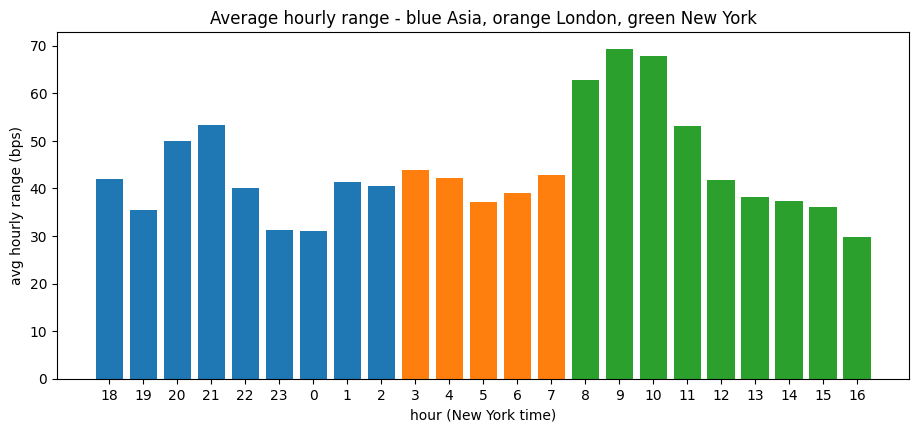

In [9]:
hourly = q("""
SELECT hour, session, AVG((high - low) / open * 10000) AS avg_range_bps
FROM gold_hourly WHERE session <> 'Closed'
GROUP BY hour, session
""")
order = list(range(18, 24)) + list(range(0, 17))
hourly = hourly.set_index("hour").loc[[x for x in order if x in hourly["hour"].values]].reset_index()
colors = hourly["session"].map({"Asia": "tab:blue", "London": "tab:orange", "New York": "tab:green"})

plt.bar(range(len(hourly)), hourly["avg_range_bps"], color=colors)
plt.xticks(range(len(hourly)), hourly["hour"])
plt.xlabel("hour (New York time)")
plt.ylabel("avg hourly range (bps)")
plt.title("Average hourly range - blue Asia, orange London, green New York")
plt.show()

### Is the high/low location different from chance?
Comparing a session's share of highs/lows to its share of *hours* is the wrong benchmark. For a random walk, the maximum and minimum are most likely to sit near the **start or end** of the window (the arcsine law), so the first session (Asia) and the last (New York) would collect extra highs and lows even if nothing special happened there.

The null model below simulates 20,000 random-walk days that have gold's actual hour-by-hour volatility profile (so the 08:00 news spike is built in), records which session holds each simulated high and low, and compares that to what really happened with a chi-square test.

In [10]:
SESSION_ORDER = list(range(18, 24)) + list(range(0, 17))
full = gh[gh["session"] != "Closed"].copy()
full = full[full.groupby("trading_date")["ts"].transform("size") >= 20]
full["lr"] = np.log(full["close"] / full["open"])
n_days = full["trading_date"].nunique()

hi_sess = full.loc[full.groupby("trading_date")["high"].idxmax(), "session"]
lo_sess = full.loc[full.groupby("trading_date")["low"].idxmin(), "session"]

# Random walk with the observed hourly volatility profile, 12 sub-steps per hour
sigma = full.groupby("hour")["lr"].std()
sigma = sigma.reindex([h for h in SESSION_ORDER if h in sigma.index])
hrs = sigma.index.to_numpy()
sess_of_hour = np.select([(hrs >= 18) | (hrs < 3), hrs < 8], ["Asia", "London"], "New York")
SUB, N_SIM = 12, 20000
step_sd = np.repeat(sigma.to_numpy() / np.sqrt(SUB), SUB)
rng = np.random.default_rng(SEED)
paths = np.cumsum(rng.standard_normal((N_SIM, len(step_sd))) * step_sd, axis=1)
paths = np.hstack([np.zeros((N_SIM, 1)), paths])                 # the day's opening price
hour_of_step = np.concatenate([[0], np.repeat(np.arange(len(hrs)), SUB)])
null_hi = pd.Series(sess_of_hour[hour_of_step[paths.argmax(axis=1)]]).value_counts(normalize=True)
null_lo = pd.Series(sess_of_hour[hour_of_step[paths.argmin(axis=1)]]).value_counts(normalize=True)

sessions = ["Asia", "London", "New York"]
hl = pd.DataFrame({
    "pct_of_hours": full["session"].value_counts(normalize=True),
    "high_observed": hi_sess.value_counts(normalize=True),
    "high_random_walk": null_hi,
    "low_observed": lo_sess.value_counts(normalize=True),
    "low_random_walk": null_lo,
}).reindex(sessions).fillna(0).mul(100).round(1)
print(hl)

for side, obs, null in [("high", hi_sess, null_hi), ("low", lo_sess, null_lo)]:
    o = obs.value_counts().reindex(sessions).fillna(0)
    e = null.reindex(sessions).fillna(0) * o.sum()
    chi = stats.chisquare(o, e)
    print(f"day's {side}: chi-square vs random walk = {chi.statistic:.1f}, p = {chi.pvalue:.4f}  (n = {int(o.sum())} days)")

          pct_of_hours  high_observed  high_random_walk  low_observed  low_random_walk
Asia              39.1           37.4              39.8          46.4             39.6
London            21.7           10.7              10.7          10.5             11.2
New York          39.1           51.9              49.6          43.1             49.2
day's high: chi-square vs random walk = 1.2, p = 0.5532  (n = 478 days)
day's low: chi-square vs random walk = 9.4, p = 0.0090  (n = 478 days)


**Findings.** New York covers about 72% ⟳ of the daily range on average, and the 08:00-10:00 NY hours are the biggest bars of the day (~65-70 bps ⟳ each), which is when US data comes out. The day's high is made in the NY session on about half of all days, and Asia makes the low on ~46% ⟳ of days; London holds only ~11% ⟳ of highs and lows. There is a bump at 20:00-21:00 NY time, around the Shanghai open.

**What the null model changes.** Part of this pattern is mechanical: because Asia opens the day and New York closes it, a pure random walk already puts more highs and lows there. The meaningful result is the *gap* between the observed and random-walk columns, and the chi-square p-value says whether that gap is bigger than chance. If London is still under-represented relative to the random walk, London really is a quieter "drift" session; if not, the earlier "half of what you'd expect" claim was an artefact of the wrong benchmark.

*Limitation:* ~2 years of hourly data (Yahoo's cap), all of it inside the 2024-26 bull market.

## 2. Does the London breakout of the Asian range work?
If London breaks above the Asian high (or below the Asian low), enter and exit at the NY close. Is the average trade positive after costs?

Three corrections versus a naive backtest:
1. **Realistic fill.** If the break bar *opens* beyond the Asian level (a gap), a stop order fills at the open, not at the level. Assuming a fill at the level overstates P&L.
2. **Drift adjustment.** All hourly data sits in a strong uptrend, so any long trade looks good. I subtract gold's average hourly drift over the hours each trade is held, which separates the setup's edge from "being long gold in 2024-26".
3. **Inference.** Bootstrap confidence intervals on the average trade, and a cost sensitivity, instead of a single p-value.

In [11]:
con.executescript("""
DROP VIEW IF EXISTS asian_breakout;
CREATE VIEW asian_breakout AS
WITH asia AS (
    SELECT trading_date, MAX(high) AS asia_high, MIN(low) AS asia_low
    FROM gold_hourly WHERE session = 'Asia'
    GROUP BY trading_date HAVING COUNT(*) >= 7
),
first_break AS (
    SELECT h.trading_date,
           MIN(CASE WHEN h.high > a.asia_high THEN h.ts END) AS first_up,
           MIN(CASE WHEN h.low < a.asia_low THEN h.ts END) AS first_down
    FROM gold_hourly h JOIN asia a USING (trading_date)
    WHERE h.session = 'London'
    GROUP BY h.trading_date
),
day_close AS (
    SELECT trading_date, close AS day_close, ts AS close_ts
    FROM (SELECT trading_date, close, ts,
                 ROW_NUMBER() OVER (PARTITION BY trading_date ORDER BY ts DESC) AS rn
          FROM gold_hourly WHERE session = 'New York')
    WHERE rn = 1
),
labelled AS (
    SELECT a.trading_date, a.asia_high, a.asia_low, c.day_close, c.close_ts, f.first_up, f.first_down,
           CASE
               WHEN f.first_up IS NULL AND f.first_down IS NULL THEN 'no break'
               WHEN f.first_down IS NULL OR f.first_up < f.first_down THEN 'up'
               WHEN f.first_up IS NULL OR f.first_down < f.first_up THEN 'down'
               ELSE 'both same hour'
           END AS break_dir
    FROM asia a JOIN first_break f USING (trading_date) JOIN day_close c USING (trading_date)
),
entries AS (
    SELECT l.*,
           CASE l.break_dir WHEN 'up' THEN l.first_up WHEN 'down' THEN l.first_down END AS entry_ts
    FROM labelled l
),
priced AS (
    SELECT e.*,
           CASE e.break_dir WHEN 'up' THEN e.asia_high WHEN 'down' THEN e.asia_low END AS level_px,
           -- a stop order fills at the bar's open if price gapped through the level
           CASE e.break_dir WHEN 'up' THEN MAX(e.asia_high, b.open)
                            WHEN 'down' THEN MIN(e.asia_low, b.open) END AS entry_px,
           (julianday(e.close_ts) - julianday(e.entry_ts)) * 24 + 1 AS hours_held
    FROM entries e LEFT JOIN gold_hourly b ON b.ts = e.entry_ts
)
SELECT trading_date, break_dir, asia_high, asia_low, entry_ts, level_px, entry_px, day_close, hours_held,
       CASE break_dir WHEN 'up' THEN 10000.0 * (day_close - level_px) / level_px
                      WHEN 'down' THEN 10000.0 * (level_px - day_close) / level_px END AS pnl_naive_bps,
       CASE break_dir WHEN 'up' THEN 10000.0 * (day_close - entry_px) / entry_px
                      WHEN 'down' THEN 10000.0 * (entry_px - day_close) / entry_px END AS pnl_bps
FROM priced;
""")

q("""
SELECT break_dir,
       COUNT(*) AS days,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_days,
       ROUND(100.0 * AVG(entry_px <> level_px), 1) AS pct_gap_fills,
       ROUND(100.0 * AVG(pnl_bps > 0), 1) AS win_rate,
       ROUND(AVG(pnl_naive_bps), 1) AS avg_pnl_naive_bps,
       ROUND(AVG(pnl_bps), 1) AS avg_pnl_bps
FROM asian_breakout
GROUP BY break_dir
ORDER BY days DESC
""")

,break_dir,days,pct_days,pct_gap_fills,win_rate,avg_pnl_naive_bps,avg_pnl_bps
0,up,192,40.1,0.0,57.8,13.6,13.6
1,down,150,31.3,0.0,48.7,6.2,6.2
2,no break,135,28.2,NaN,NaN,NaN,NaN
3,both same hour,2,0.4,NaN,NaN,NaN,NaN


In [12]:
def boot_mean_ci(x, n_boot=5000, seed=SEED):
    x = np.asarray(x)
    r = np.random.default_rng(seed)
    means = x[r.integers(0, len(x), (n_boot, len(x)))].mean(axis=1)
    return np.percentile(means, [2.5, 97.5])

COST = 2  # bps per round trip (spread + slippage), checked at 0.5 and 5 below
trades = q("""SELECT trading_date, break_dir, pnl_naive_bps, pnl_bps, hours_held
              FROM asian_breakout WHERE break_dir IN ('up', 'down') ORDER BY trading_date""")
trades["trading_date"] = pd.to_datetime(trades["trading_date"])
drift_bps_per_hour = 1e4 * full["lr"].mean()
direction = np.where(trades["break_dir"] == "up", 1, -1)
trades["pnl_drift_adj_bps"] = trades["pnl_bps"] - direction * drift_bps_per_hour * trades["hours_held"]
print(f"gold's average drift over the hourly sample: {drift_bps_per_hour:.2f} bps per hour")

rows = []
for d in ["up", "down"]:
    t = trades[trades["break_dir"] == d]
    for version, col in [("naive fill", "pnl_naive_bps"), ("realistic fill", "pnl_bps"),
                         ("realistic fill, drift-adjusted", "pnl_drift_adj_bps")]:
        net = t[col] - COST
        lo, hi = boot_mean_ci(net)
        rows.append({"direction": d, "version": version, "trades": len(t), "avg_net_bps": net.mean(),
                     "ci95_low": lo, "ci95_high": hi, "win_rate_%": 100 * (net > 0).mean(),
                     "p_value": stats.ttest_1samp(net, 0).pvalue})
breakout = pd.DataFrame(rows)
breakout["p_holm"] = multipletests(breakout["p_value"], method="holm")[1]
breakout.round(3)

gold's average drift over the hourly sample: 0.55 bps per hour


,direction,version,trades,avg_net_bps,ci95_low,ci95_high,win_rate_%,p_value,p_holm
0,up,naive fill,192,11.566,-1.779,24.552,57.812,0.086,0.517
1,up,realistic fill,192,11.566,-1.779,24.552,57.812,0.086,0.517
2,up,"realistic fill, drift-adjusted",192,4.402,-8.954,17.371,54.167,0.512,1.000
3,down,naive fill,150,4.152,-14.715,23.160,47.333,0.664,1.000
4,down,realistic fill,150,4.152,-14.715,23.160,47.333,0.664,1.000
5,down,"realistic fill, drift-adjusted",150,11.275,-7.594,30.283,52.667,0.239,0.958


average net trade (realistic fill, drift-adjusted) by cost assumption:
           cost 0.5 bps  cost 2 bps  cost 5 bps
break_dir                                      
down               12.8        11.3         8.3
up                  5.9         4.4         1.4


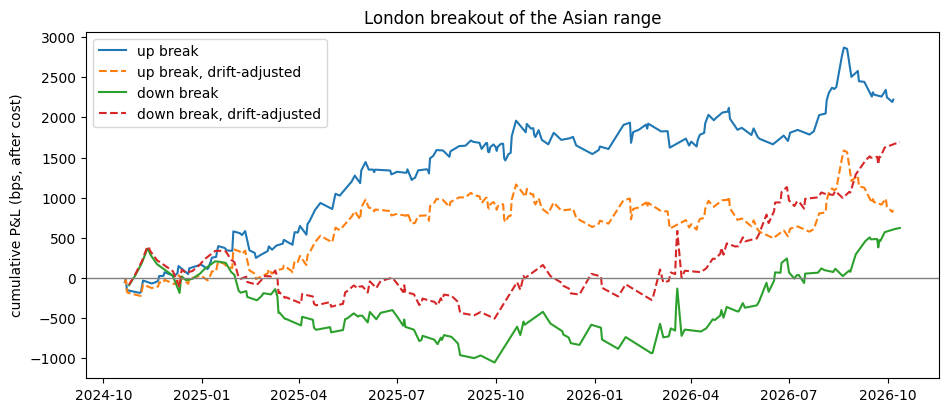

In [13]:
sens = pd.DataFrame({f"cost {c} bps": trades.groupby("break_dir")["pnl_drift_adj_bps"].apply(lambda x: (x - c).mean())
                     for c in [0.5, 2, 5]}).round(1)
print("average net trade (realistic fill, drift-adjusted) by cost assumption:")
print(sens)

for d in ["up", "down"]:
    t = trades[trades["break_dir"] == d]
    plt.plot(t["trading_date"], (t["pnl_bps"] - COST).cumsum(), label=f"{d} break")
    plt.plot(t["trading_date"], (t["pnl_drift_adj_bps"] - COST).cumsum(), ls="--", label=f"{d} break, drift-adjusted")
plt.axhline(0, color="grey", lw=1)
plt.legend()
plt.ylabel("cumulative P&L (bps, after cost)")
plt.title("London breakout of the Asian range")
plt.show()

**Findings.** London breaks the Asian range on ~72% ⟳ of days. In the original backtest, buying upside breaks averaged about +12 bps ⟳ a trade after costs with a ~58% win rate, with p ≈ 0.09, so not significant even before corrections. Selling downside breaks did basically nothing.

**What the corrections show.** The realistic-fill column shows how much of the naive P&L came from fills that were not actually available after a gap. The drift-adjusted rows test my earlier guess directly: if the upside "edge" is mostly gold's bull run, the drift-adjusted average shrinks towards zero and its 95% interval straddles zero. That is the number to quote, not the raw average. With ~2 years of data the confidence interval is wide, so the honest conclusion is "no evidence of an edge beyond trend exposure", not "it works at 90% confidence". Remaining optimism: hourly bars hide the order of moves inside the hour, so a stop could have been hit before the break.

## 3. How much do FOMC, CPI and NFP days move gold?
Each day's range is divided by the average range of the previous 20 days, so 1.0 = a normal day and different years are comparable. Mann-Whitney test because daily ranges are skewed with fat tails.

Corrections versus the first version: days with two releases (e.g. CPI on an FOMC day) are kept out of the single-event tests so effects are not double-counted; the three tests get a Holm correction; effect sizes come with bootstrap intervals; and in the before/after chart, neighbouring days that are themselves release days are skipped (otherwise "FOMC +1" can just be a CPI day).

In [14]:
con.executescript("""
DROP VIEW IF EXISTS daily_metrics;
CREATE VIEW daily_metrics AS
WITH px AS (
    SELECT date, high, low, close, LAG(close) OVER (ORDER BY date) AS prev_close FROM gold_daily
),
m AS (
    SELECT date,
           100.0 * (close / prev_close - 1) AS ret_pct,
           100.0 * (high - low) / prev_close AS range_pct
    FROM px WHERE prev_close IS NOT NULL
)
SELECT date, ret_pct, range_pct,
       range_pct / AVG(range_pct) OVER (ORDER BY date ROWS BETWEEN 20 PRECEDING AND 1 PRECEDING) AS rel_range,
       ROW_NUMBER() OVER (ORDER BY date) AS day_n
FROM m;
""")

q("""
WITH tags AS (
    SELECT date, CASE WHEN COUNT(*) > 1 THEN 'multiple' ELSE MAX(event) END AS day_type
    FROM events GROUP BY date
)
SELECT COALESCE(t.day_type, 'no event') AS day_type,
       COUNT(*) AS days,
       ROUND(AVG(d.rel_range), 2) AS avg_rel_range,
       ROUND(AVG(ABS(d.ret_pct)), 2) AS avg_abs_move_pct
FROM daily_metrics d LEFT JOIN tags t USING (date)
WHERE d.day_n > 21
GROUP BY 1
ORDER BY avg_rel_range DESC
""")

,day_type,days,avg_rel_range,avg_abs_move_pct
0,multiple,10,1.52,0.35
1,NFP,190,1.38,0.95
2,FOMC,118,1.23,0.64
3,CPI,181,1.06,0.72
4,no event,3550,1.00,0.77


In [15]:
dm = q("SELECT date, day_n, rel_range FROM daily_metrics WHERE day_n > 21")
dm["date"] = pd.to_datetime(dm["date"])
ev_by_day = events.groupby("date")["event"].agg(list)
single = ev_by_day[ev_by_day.str.len() == 1].str[0]          # date -> event, single-event days only
is_event_day = dm["date"].isin(events["date"])
normal = dm.loc[~is_event_day, "rel_range"].to_numpy()

r = np.random.default_rng(SEED)
boot_normal = np.median(normal[r.integers(0, len(normal), (2000, len(normal)))], axis=1)
rows = []
for ev in ["FOMC", "CPI", "NFP"]:
    x = dm.loc[dm["date"].isin(single[single == ev].index), "rel_range"].to_numpy()
    boot_x = np.median(x[r.integers(0, len(x), (2000, len(x)))], axis=1)
    ratio_ci = np.percentile(boot_x / boot_normal, [2.5, 97.5])
    rows.append({"event": ev, "days": len(x), "median_rel_range": np.median(x), "normal_median": np.median(normal),
                 "median_ratio": np.median(x) / np.median(normal), "ratio_ci95_low": ratio_ci[0],
                 "ratio_ci95_high": ratio_ci[1],
                 "p_value": stats.mannwhitneyu(x, normal, alternative="greater").pvalue})
event_tests = pd.DataFrame(rows)
event_tests["p_holm"] = multipletests(event_tests["p_value"], method="holm")[1]
event_tests.round(4)

,event,days,median_rel_range,normal_median,median_ratio,ratio_ci95_low,ratio_ci95_high,p_value,p_holm
0,FOMC,118,1.1392,0.8708,1.3083,1.1859,1.5024,0.0000,0.0000
1,CPI,181,0.9594,0.8708,1.1018,0.9769,1.2061,0.0272,0.0272
2,NFP,190,1.2246,0.8708,1.4064,1.2954,1.5280,0.0000,0.0000


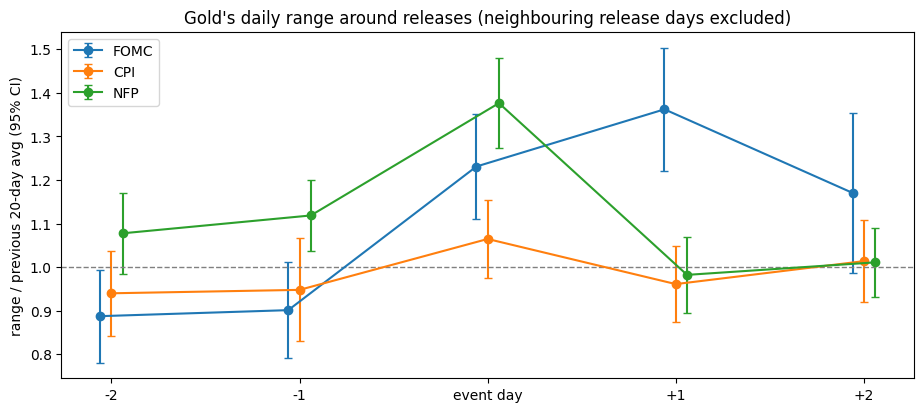

In [16]:
rel_by_n = dm.set_index("day_n")["rel_range"]
event_day_ns = set(dm.loc[is_event_day, "day_n"])
rows = []
for ev in ["FOMC", "CPI", "NFP"]:
    for n0 in dm.loc[dm["date"].isin(single[single == ev].index), "day_n"]:
        for k in range(-2, 3):
            n = n0 + k
            if (k != 0 and n in event_day_ns) or n not in rel_by_n.index:
                continue                     # neighbour is itself a release day, or outside the sample
            rows.append((ev, k, rel_by_n[n]))
around = pd.DataFrame(rows, columns=["event", "offset", "rel_range"])
summary = around.groupby(["event", "offset"])["rel_range"].agg(["mean", "sem", "count"]).reset_index()

for i, ev in enumerate(["FOMC", "CPI", "NFP"]):
    a = summary[summary["event"] == ev]
    plt.errorbar(a["offset"] + (i - 1) * 0.06, a["mean"], yerr=1.96 * a["sem"], marker="o", capsize=3, label=ev)
plt.axhline(1, color="grey", ls="--", lw=1)
plt.xticks(range(-2, 3), ["-2", "-1", "event day", "+1", "+2"])
plt.ylabel("range / previous 20-day avg (95% CI)")
plt.title("Gold's daily range around releases (neighbouring release days excluded)")
plt.legend()
plt.show()

In [17]:
# Release-hour effect: 08:00 bar holds the 08:30 CPI/NFP release, 14:00 bar holds the FOMC statement
hh = gh[gh["hour"].isin([8, 14])].copy()
hh["range_bps"] = (hh["high"] - hh["low"]) / hh["open"] * 1e4
quiet = ~hh["trading_date"].isin(events["date"])
rows = []
for ev, hr in [("FOMC", 14), ("CPI", 8), ("NFP", 8)]:
    x = hh.loc[(hh["hour"] == hr) & hh["trading_date"].isin(single[single == ev].index), "range_bps"]
    base_ = hh.loc[(hh["hour"] == hr) & quiet, "range_bps"]
    if len(x) < 3:
        continue
    rows.append({"event": ev, "hour": hr, "event_bars": len(x), "median_bps": x.median(),
                 "other_days_median_bps": base_.median(), "ratio": x.median() / base_.median(),
                 "p_value": stats.mannwhitneyu(x, base_, alternative="greater").pvalue})
release_hour = pd.DataFrame(rows)
release_hour.round(3)

,event,hour,event_bars,median_bps,other_days_median_bps,ratio,p_value
0,FOMC,14,16,98.128,24.545,3.998,0.0
1,CPI,8,22,76.618,48.815,1.570,0.0
2,NFP,8,21,105.263,48.815,2.156,0.0


**Findings.** All three release types raise gold's range; NFP days are the biggest at ~1.4x ⟳ a normal day, FOMC ~1.25x ⟳, CPI only ~1.06x ⟳ on average. In the release hour itself, the 14:00 bar on FOMC days is ~3.4x ⟳ a normal 14:00 bar, and the 08:00 bar is ~1.9x ⟳ on NFP and ~1.5x ⟳ on CPI days. NFP volatility is gone the next day, while after FOMC the range stays elevated for another day or two.

**How to read the corrected tables.** Use the Holm-adjusted p-values and the median-ratio intervals: an interval that excludes 1.0 means the effect is real at the 5% level after accounting for testing three events. The hourly tests have only ~2 years (≈16 FOMC, ≈24 CPI/NFP bars), so treat their p-values as indicative. The FOMC spill-over claim now holds only if the +1/+2 points stay above 1.0 with error bars clear of the line, since nearby CPI days are no longer mixed in.

## 4. Does gold still follow the dollar and real yields?
Gold usually moves against the dollar and against real yields (gold pays no interest). I use correlations of *changes* (correlating price levels of trending series gives spurious results), rolling over 1 year, and compare 2010-2021 with 2022 onwards.

Two corrections: (1) the three series close at different times (gold settles ~13:30 NY, Treasury yields ~15:30-16:00, DXY ~17:00), so daily correlations are biased towards zero; weekly and monthly changes reduce that. (2) The era comparison gets a formal test (Fisher z) and the sensitivity gets HAC (Newey-West) confidence intervals, which allow for autocorrelation and changing volatility.

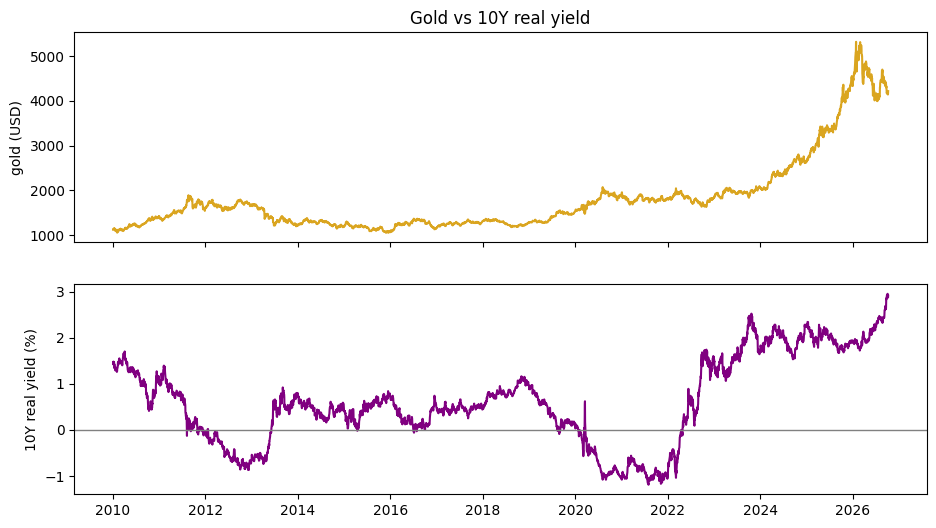

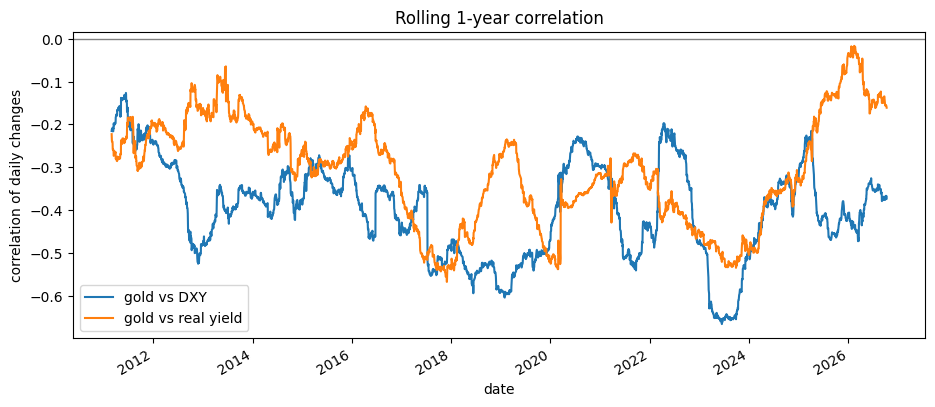

In [18]:
mm = q("""
SELECT g.date, g.close AS gold, m.dxy, r.real_yield
FROM gold_daily g
JOIN macro_daily m USING (date)
JOIN real_yield r USING (date)
WHERE m.dxy IS NOT NULL
ORDER BY g.date
""")
mm["date"] = pd.to_datetime(mm["date"])
mm = mm.set_index("date")

fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax[0].plot(mm.index, mm["gold"], color="goldenrod")
ax[0].set_ylabel("gold (USD)")
ax[1].plot(mm.index, mm["real_yield"], color="purple")
ax[1].axhline(0, color="grey", lw=1)
ax[1].set_ylabel("10Y real yield (%)")
ax[0].set_title("Gold vs 10Y real yield")
plt.show()

def changes(levels):
    return pd.DataFrame({"gold": levels["gold"].pct_change() * 100,
                         "dxy": levels["dxy"].pct_change() * 100,
                         "real_yield_bp": levels["real_yield"].diff() * 100}).dropna()

chg = changes(mm)
chg["gold"].rolling(252).corr(chg["dxy"]).plot(label="gold vs DXY")
chg["gold"].rolling(252).corr(chg["real_yield_bp"]).plot(label="gold vs real yield")
plt.axhline(0, color="grey", lw=1)
plt.ylabel("correlation of daily changes")
plt.title("Rolling 1-year correlation")
plt.legend()
plt.show()

In [19]:
def fisher_p(r1, n1, r2, n2):
    z = (np.arctanh(r1) - np.arctanh(r2)) / np.sqrt(1 / (n1 - 3) + 1 / (n2 - 3))
    return 2 * stats.norm.sf(abs(z))

rows = []
for horizon, levels, lags in [("daily", mm, 5), ("weekly", mm.resample("W-FRI").last(), 4),
                              ("monthly", mm.resample("ME").last(), 3)]:
    c = changes(levels)
    eras = {"2010-2021": c[:"2021"], "2022-now": c["2022":]}
    stats_by_era = {}
    for era, e in eras.items():
        ols = sm.OLS(e["gold"], sm.add_constant(e["real_yield_bp"])).fit(cov_type="HAC", cov_kwds={"maxlags": lags})
        ci = ols.conf_int().loc["real_yield_bp"]
        stats_by_era[era] = (e["gold"].corr(e["real_yield_bp"]), len(e))
        rows.append({"horizon": horizon, "era": era, "n": len(e),
                     "corr_real_yield": e["gold"].corr(e["real_yield_bp"]),
                     "corr_dxy": e["gold"].corr(e["dxy"]),
                     "gold_%_per_10bp_ry": 10 * ols.params["real_yield_bp"],
                     "ci95_low": 10 * ci[0], "ci95_high": 10 * ci[1]})
    (r1, n1), (r2, n2) = stats_by_era.values()
    rows[-1]["p_corr_changed"] = fisher_p(r1, n1, r2, n2)
links = pd.DataFrame(rows)
print(links.round(3).to_string(index=False))

g0, g1 = mm["gold"]["2022"].iloc[0], mm["gold"].iloc[-1]
y0, y1 = mm["real_yield"]["2022"].iloc[0], mm["real_yield"].iloc[-1]
ry_peak = mm["real_yield"]["2022":].max()
print(f"\nsince Jan 2022: gold {g0:.0f} -> {g1:.0f} ({100 * (g1 / g0 - 1):+.0f}%), "
      f"real yield {y0:.2f}% -> {y1:.2f}% (peak {ry_peak:.2f}%)")

horizon       era    n  corr_real_yield  corr_dxy  gold_%_per_10bp_ry  ci95_low  ci95_high  p_corr_changed
  daily 2010-2021 2847           -0.278    -0.348              -0.661    -0.781     -0.542             NaN
  daily  2022-now 1191           -0.273    -0.393              -0.583    -0.693     -0.474           0.874
 weekly 2010-2021  623           -0.447    -0.483              -1.018    -1.252     -0.784             NaN
 weekly  2022-now  249           -0.257    -0.368              -0.527    -0.827     -0.226           0.004
monthly 2010-2021  143           -0.520    -0.365              -1.403    -1.778     -1.028             NaN
monthly  2022-now   58           -0.424    -0.525              -0.765    -1.197     -0.333           0.435

since Jan 2022: gold 1800 -> 4216 (+134%), real yield -0.97% -> 2.91% (peak 2.95%)


**Findings.** Day to day, the link held: the correlation with real yields is about -0.27 ⟳ in both periods and with the dollar about -0.35 to -0.39 ⟳, and a +10 bp move in real yields still means roughly -0.6% ⟳ for gold that day. If the Fisher-test p-value for the daily horizon is large, "nothing broke at the daily horizon" is now a tested statement rather than an eyeballed one. The weekly and monthly rows show whether the link is *stronger* once the closing-time mismatch is removed, which is the more accurate size of the effect.

In levels, the relationship fell apart: since 2022 real yields rose from about -1% to a peak shown in the printout ⟳, yet gold more than doubled. So something else is driving the long-term trend (central-bank buying is the usual explanation), while yields and the dollar still explain much of the daily noise. Note this is an observation about two eras, not a causal estimate.

## 5. Which days were actually abnormal?
Isolation Forest on six features (gold return, range, opening gap, DXY move, real-yield change, VIX change), each scaled against its own past 60 days. Unsupervised because there are no labels for "anomaly", and unlike a simple 3-sigma rule it can catch unusual *combinations*.

Checks added: the 1% contamination rate is a choice, not a finding, so I show how the flagged set changes at 0.5% and 2% and across random seeds; each flagged day gets a "driver" (the feature that is most extreme that day) so a reader can see *why* it was flagged; and days where the opening gap is extreme but the day's return is not are tagged as possible contract-roll artefacts. This is a retrospective labelling exercise, so fitting on the full history is appropriate; a live alert system would have to refit on past data only.

In [20]:
from sklearn.ensemble import IsolationForest

base = q("""
SELECT g.date, g.open, g.high, g.low, g.close, m.dxy, m.vix, r.real_yield
FROM gold_daily g
LEFT JOIN macro_daily m USING (date)
LEFT JOIN real_yield r USING (date)
ORDER BY g.date
""")
base["date"] = pd.to_datetime(base["date"])
base = base.set_index("date")
base[["dxy", "vix", "real_yield"]] = base[["dxy", "vix", "real_yield"]].ffill(limit=3)

ret = base["close"].pct_change()
rng_ = (base["high"] - base["low"]) / base["close"].shift(1)
past_vol = ret.rolling(60).std().shift(1)
dxy_ret = base["dxy"].pct_change()
ry_chg = base["real_yield"].diff()

feat = pd.DataFrame({
    "gold_ret_z": ret / past_vol,
    "range_vs_20d": rng_ / rng_.rolling(20).mean().shift(1),
    "gap_z": (base["open"] / base["close"].shift(1) - 1) / past_vol,
    "dxy_z": dxy_ret / dxy_ret.rolling(60).std().shift(1),
    "real_yield_z": ry_chg / ry_chg.rolling(60).std().shift(1),
    "vix_chg_pct": base["vix"].pct_change() * 100,
}).replace([np.inf, -np.inf], np.nan).dropna()
cols = list(feat.columns)

iso = IsolationForest(n_estimators=500, contamination=0.01, random_state=SEED).fit(feat[cols])
feat["score"] = -iso.score_samples(feat[cols])
feat["anomaly"] = iso.predict(feat[cols]) == -1
feat["three_sigma"] = feat["gold_ret_z"].abs() > 3

# Driver = feature furthest from its own typical value (robust z: median / MAD)
robust_z = (feat[cols] - feat[cols].median()) / (1.4826 * (feat[cols] - feat[cols].median()).abs().median())
feat["driver"] = robust_z.abs().idxmax(axis=1)
feat["possible_roll"] = (feat["gap_z"].abs() > 3) & (feat["gold_ret_z"].abs() < 1.5)

k = int(feat["anomaly"].sum())
top_k_by_return = feat["gold_ret_z"].abs().nlargest(k).index
print(f"isolation forest flags {k} days; 3-sigma rule flags {int(feat['three_sigma'].sum())}; "
      f"overlap with the {k} largest |return| days: {feat.loc[feat['anomaly']].index.isin(top_k_by_return).sum()}")
print("flagged days that look like contract-roll gaps:", int((feat["anomaly"] & feat["possible_roll"]).sum()))

isolation forest flags 41 days; 3-sigma rule flags 57; overlap with the 41 largest |return| days: 17
flagged days that look like contract-roll gaps: 0


In [21]:
# Stability: does the flagged set depend on the contamination choice or the random seed?
ref = set(feat.index[feat["anomaly"]])
rows = []
for c in [0.005, 0.01, 0.02]:
    flagged = set(feat.index[IsolationForest(n_estimators=500, contamination=c, random_state=SEED)
                             .fit(feat[cols]).predict(feat[cols]) == -1])
    rows.append({"contamination": c, "flagged": len(flagged), "share_of_1%_set_kept": len(flagged & ref) / len(ref)})
stab = pd.DataFrame(rows)
jacc = []
for s in range(5):
    f = set(feat.index[IsolationForest(n_estimators=500, contamination=0.01, random_state=s)
                       .fit(feat[cols]).predict(feat[cols]) == -1])
    jacc.append(len(f & ref) / len(f | ref))
print(stab.round(3).to_string(index=False))
print(f"Jaccard overlap of the 1% set across 5 other seeds: mean {np.mean(jacc):.2f}, min {np.min(jacc):.2f}")

top = feat[feat["anomaly"]].sort_values("score", ascending=False).head(15).copy()
top["gold_ret_%"] = (ret.reindex(top.index) * 100).round(2)
top[["gold_ret_%", "range_vs_20d", "gap_z", "dxy_z", "real_yield_z", "vix_chg_pct", "driver",
     "three_sigma", "possible_roll"]].round(2)

 contamination  flagged  share_of_1%_set_kept
         0.005       21                 0.512
         0.010       41                 1.000
         0.020       81                 1.000
Jaccard overlap of the 1% set across 5 other seeds: mean 0.82, min 0.74


,gold_ret_%,range_vs_20d,gap_z,dxy_z,real_yield_z,vix_chg_pct,driver,three_sigma,possible_roll
date,,,,,,,,,
2016-06-24,4.66,6.28,-0.64,4.88,-2.53,49.33,range_vs_20d,True,False
2013-04-15,-9.35,9.09,-1.67,0.41,-0.33,43.20,range_vs_20d,True,False
2011-08-08,3.72,2.19,2.42,0.42,-2.47,50.00,vix_chg_pct,True,False
2025-04-03,-1.41,3.02,1.12,-3.62,-2.30,39.56,vix_chg_pct,False,False
2020-03-16,-1.97,3.63,2.76,-1.48,-0.73,42.99,gap_z,False,False
2016-11-14,-3.50,1.56,-3.64,3.12,3.69,-1.76,gap_z,True,False
2010-05-20,-2.18,0.75,-1.80,-3.16,2.42,36.48,gap_z,False,False
2026-01-30,-10.78,5.44,1.24,2.49,0.38,3.32,range_vs_20d,True,False
2013-06-20,-6.38,3.09,-1.06,1.03,3.63,23.14,range_vs_20d,True,False


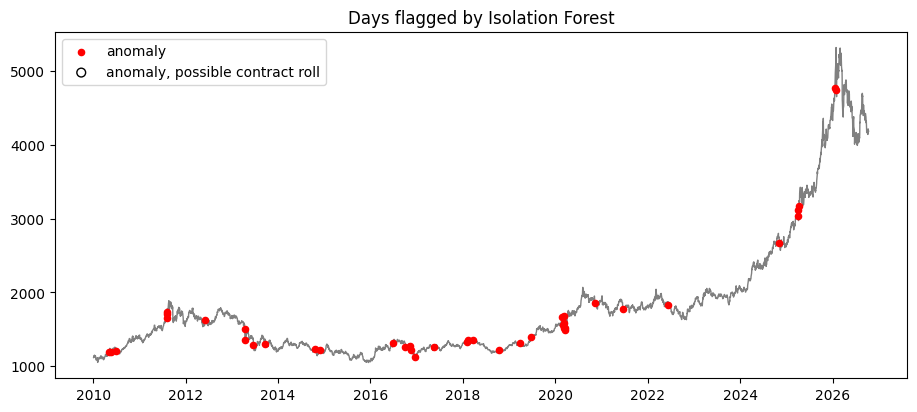

In [22]:
plt.plot(base.index, base["close"], color="grey", lw=1)
flag = feat.index[feat["anomaly"] & ~feat["possible_roll"]]
roll = feat.index[feat["anomaly"] & feat["possible_roll"]]
plt.scatter(flag, base.loc[flag, "close"], color="red", s=20, zorder=3, label="anomaly")
plt.scatter(roll, base.loc[roll, "close"], facecolors="none", edgecolors="black", s=40, zorder=3,
            label="anomaly, possible contract roll")
plt.legend()
plt.title("Days flagged by Isolation Forest")
plt.show()

**Findings.** About 1% of days are flagged (41 ⟳ in my run; that count is set by the contamination parameter, not discovered). Most overlap with the largest-return days; the rest are days where gold itself was not extreme but the *combination* was (VIX spikes, big opening gaps, real-yield jumps), and the driver column shows which. The top-scoring days are recognisable events, e.g. the Brexit vote (24 Jun 2016), the April 2013 gold crash, the US downgrade sell-off (8 Aug 2011), the taper tantrum (20 Jun 2013), March 2020, the 2024 US election (6 Nov 2024) and the April 2025 tariff announcement ⟳ (verify each against the printed table).

The stability table matters for credibility: if most of the 1% set survives at 0.5%/2% and across seeds, the list is robust; days flagged as possible contract rolls should be treated as data artefacts, not market events.

## 6. Can tomorrow's volatility be predicted? What about direction?
Target = 1 if tomorrow's range is bigger than the median range of the last 20 days. Features only use data known at today's close, plus whether tomorrow is an FOMC / CPI / NFP day (the calendar is known in advance).

**Models compared** (all walk-forward on 2010-2023, never training on the future, then a 2024+ holdout):
- *Naive baseline*: tomorrow looks like today (today's range vs its median).
- *HAR*: the standard volatility-forecasting benchmark (Corsi 2009): a linear model of log range on its daily, weekly and monthly averages. A new model should beat this, not just the naive baseline.
- *Logistic regression* and *XGBoost*, with their main hyperparameter chosen by walk-forward CV on the training years only.

**Evaluation upgrades:** per-fold AUC (stability), block-bootstrap confidence intervals on holdout AUC and on the *difference* to the baselines (a 0.003 AUC gap is not a win unless its interval excludes zero), calibration (Brier score and reliability curve, because position sizing uses the probabilities, not just the ranking), a decision threshold chosen on training data rather than on the holdout, and an economic check of whether acting on the forecast actually lowers risk.

In [23]:
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import roc_auc_score, roc_curve, brier_score_loss, log_loss
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier

d = base.copy()
d["ret"] = d["close"].pct_change() * 100
d["range"] = (d["high"] - d["low"]) / d["close"].shift(1) * 100
next_day = d.index.to_series().shift(-1)
next_day.iloc[-1] = d.index[-1] + pd.offsets.BDay(1)

med20 = d["range"].rolling(20).median()
X = pd.DataFrame(index=d.index)
X["range_vs_median"] = d["range"] / med20
X["range_5d_vs_20d"] = d["range"].rolling(5).mean() / d["range"].rolling(20).mean()
X["vol_5d"] = d["ret"].rolling(5).std()
X["vol_20d"] = d["ret"].rolling(20).std()
X["ret_z"] = d["ret"] / X["vol_20d"]
X["abs_ret_z"] = X["ret_z"].abs()
X["vix"] = d["vix"]
X["vix_chg_5d"] = d["vix"].pct_change(5) * 100
X["dxy_abs_move"] = d["dxy"].pct_change().abs() * 100
X["ry_abs_move"] = d["real_yield"].diff().abs() * 100
for ev in ["FOMC", "CPI", "NFP"]:
    X[f"{ev}_tomorrow"] = next_day.isin(events.loc[events["event"] == ev, "date"]).astype(int).values
X["monday_tomorrow"] = (next_day.dt.dayofweek == 0).astype(int).values
X = X.replace([np.inf, -np.inf], np.nan)

# HAR inputs (log range: daily, weekly, monthly averages)
log_range = np.log(d["range"])
H = pd.DataFrame({"har_d": log_range,
                  "har_w": np.log(d["range"].rolling(5).mean()),
                  "har_m": np.log(d["range"].rolling(22).mean())}, index=d.index)

y_vol = (d["range"].shift(-1) > med20).astype(int)
y_dir = (d["ret"].shift(-1) > 0).astype(int)
ok = X.notna().all(axis=1) & H.notna().all(axis=1) & d["range"].shift(-1).notna()
X_ok, H_ok = X[ok], H[ok]
ylr_ok = log_range.shift(-1)[ok]                 # HAR regression target: tomorrow's log range
log_med_ok = np.log(med20)[ok]
train = np.asarray(X_ok.index < "2024-01-01")
tr_pos, te_pos = np.where(train)[0], np.where(~train)[0]

# Leakage guard: every feature row must be dated strictly before the day it predicts
assert (X_ok.index < next_day[ok]).all()
print("train", len(tr_pos), "holdout", len(te_pos), " high-vol share", round(y_vol[ok].mean(), 3))

train 3349 holdout 699  high-vol share 0.485


In [24]:
def make_model(name, **kw):
    if name == "logreg":
        return make_pipeline(StandardScaler(), LogisticRegression(C=kw.get("C", 0.5), max_iter=2000))
    return XGBClassifier(n_estimators=400, max_depth=kw.get("max_depth", 3), learning_rate=0.03, subsample=0.8,
                         colsample_bytree=0.8, min_child_weight=10, random_state=SEED, n_jobs=-1)

def fit_score(name, params, fit_idx, pred_idx, y):
    """Fit on fit_idx rows of the modelling set, return scores for pred_idx rows."""
    if name == "naive baseline":
        return X_ok["range_vs_median"].iloc[pred_idx].to_numpy()
    if name == "HAR":
        m = LinearRegression().fit(H_ok.iloc[fit_idx], ylr_ok.iloc[fit_idx])
        return m.predict(H_ok.iloc[pred_idx]) - log_med_ok.iloc[pred_idx].to_numpy()
    m = make_model(name, **params).fit(X_ok.iloc[fit_idx], y.iloc[fit_idx])
    return m.predict_proba(X_ok.iloc[pred_idx])[:, 1]

tscv = TimeSeriesSplit(n_splits=5, gap=1)
folds = [(tr_pos[a], tr_pos[b]) for a, b in tscv.split(tr_pos)]

def walk_forward(name, params, y):
    aucs, oof = [], pd.Series(np.nan, index=X_ok.index)
    for fi, vi in folds:
        s = fit_score(name, params, fi, vi, y)
        aucs.append(roc_auc_score(y.iloc[vi], s))
        oof.iloc[vi] = s
    return np.array(aucs), oof

# Hyperparameters chosen on walk-forward CV inside the training years only
grid = {"logreg": [{"C": c} for c in [0.01, 0.1, 1.0]], "xgboost": [{"max_depth": m} for m in [2, 3, 4]]}
best = {}
for target, y in [("volatility", y_vol[ok]), ("direction", y_dir[ok])]:
    for name, options in grid.items():
        cv = {str(p): walk_forward(name, p, y)[0].mean() for p in options}
        best[(target, name)] = options[int(np.argmax(list(cv.values())))]
        print(f"{target:10s} {name:8s} CV AUC by setting: { {k: round(float(v), 3) for k, v in cv.items()} }")

volatility logreg   CV AUC by setting: {"{'C': 0.01}": 0.609, "{'C': 0.1}": 0.612, "{'C': 1.0}": 0.613}
volatility xgboost  CV AUC by setting: {"{'max_depth': 2}": 0.587, "{'max_depth': 3}": 0.579, "{'max_depth': 4}": 0.576}
direction  logreg   CV AUC by setting: {"{'C': 0.01}": 0.504, "{'C': 0.1}": 0.504, "{'C': 1.0}": 0.504}
direction  xgboost  CV AUC by setting: {"{'max_depth': 2}": 0.499, "{'max_depth': 3}": 0.496, "{'max_depth': 4}": 0.497}


In [25]:
def block_boot(y, s1, s2=None, n_boot=2000, block=20, seed=SEED):
    """95% CI for AUC(s1), or AUC(s1) - AUC(s2), resampling 20-day blocks to keep volatility clustering."""
    y, s1 = np.asarray(y), np.asarray(s1)
    s2 = None if s2 is None else np.asarray(s2)
    r, n = np.random.default_rng(seed), len(y)
    starts = r.integers(0, n - block + 1, (n_boot, int(np.ceil(n / block))))
    out = []
    for st in starts:
        idx = (st[:, None] + np.arange(block)).ravel()[:n]
        if y[idx].min() == y[idx].max():
            continue
        a = roc_auc_score(y[idx], s1[idx])
        out.append(a if s2 is None else a - roc_auc_score(y[idx], s2[idx]))
    return np.percentile(out, [2.5, 97.5])

results, hold, oof_store = [], {}, {}
for target, y in [("volatility", y_vol[ok]), ("direction", y_dir[ok])]:
    names = (["naive baseline", "HAR"] if target == "volatility" else []) + ["logreg", "xgboost"]
    y_te = y.iloc[te_pos]
    for name in names:
        params = best.get((target, name), {})
        aucs, oof = walk_forward(name, params, y)
        s = fit_score(name, params, tr_pos, te_pos, y)
        lo, hi = block_boot(y_te, s)
        row = {"target": target, "model": name, "params": params or "-", "wf_auc_mean": aucs.mean(),
               "wf_auc_std": aucs.std(), "wf_auc_min": aucs.min(), "holdout_auc": roc_auc_score(y_te, s),
               "holdout_ci95": f"[{lo:.3f}, {hi:.3f}]"}
        if name in ("logreg", "xgboost"):
            row["brier"] = brier_score_loss(y_te, s)
            row["log_loss"] = log_loss(y_te, s)
        results.append(row)
        hold[(target, name)], oof_store[(target, name)] = s, oof
results = pd.DataFrame(results)
print("Brier score of always predicting the base rate:",
      round(brier_score_loss(y_vol[ok].iloc[te_pos], np.full(len(te_pos), y_vol[ok].iloc[tr_pos].mean())), 4))
results.round(3)

Brier score of always predicting the base rate: 0.25


,target,model,params,wf_auc_mean,wf_auc_std,wf_auc_min,holdout_auc,holdout_ci95,brier,log_loss
0,volatility,naive baseline,-,0.558,0.020,0.537,0.607,"[0.561, 0.656]",NaN,NaN
1,volatility,HAR,-,0.595,0.020,0.567,0.644,"[0.593, 0.691]",NaN,NaN
2,volatility,logreg,{'C': 1.0},0.613,0.035,0.575,0.610,"[0.561, 0.651]",0.242,0.675
3,volatility,xgboost,{'max_depth': 2},0.587,0.030,0.560,0.617,"[0.570, 0.660]",0.239,0.669
4,direction,logreg,{'C': 0.01},0.504,0.022,0.484,0.516,"[0.468, 0.567]",0.250,0.694
5,direction,xgboost,{'max_depth': 2},0.499,0.019,0.474,0.524,"[0.476, 0.567]",0.251,0.695


In [26]:
y_te = y_vol[ok].iloc[te_pos].to_numpy()
rows = []
for model in ["logreg", "xgboost"]:
    for bench in ["naive baseline", "HAR"]:
        lo, hi = block_boot(y_te, hold[("volatility", model)], hold[("volatility", bench)])
        diff = roc_auc_score(y_te, hold[("volatility", model)]) - roc_auc_score(y_te, hold[("volatility", bench)])
        verdict = "better" if lo > 0 else "worse" if hi < 0 else "no significant difference"
        rows.append({"model": model, "vs": bench, "auc_gain": diff, "ci95_low": lo, "ci95_high": hi,
                     "verdict": verdict})
pd.DataFrame(rows).round(3)

,model,vs,auc_gain,ci95_low,ci95_high,verdict
0,logreg,naive baseline,0.003,-0.053,0.051,no significant difference
1,logreg,HAR,-0.034,-0.089,0.022,no significant difference
2,xgboost,naive baseline,0.010,-0.043,0.053,no significant difference
3,xgboost,HAR,-0.027,-0.075,0.016,no significant difference


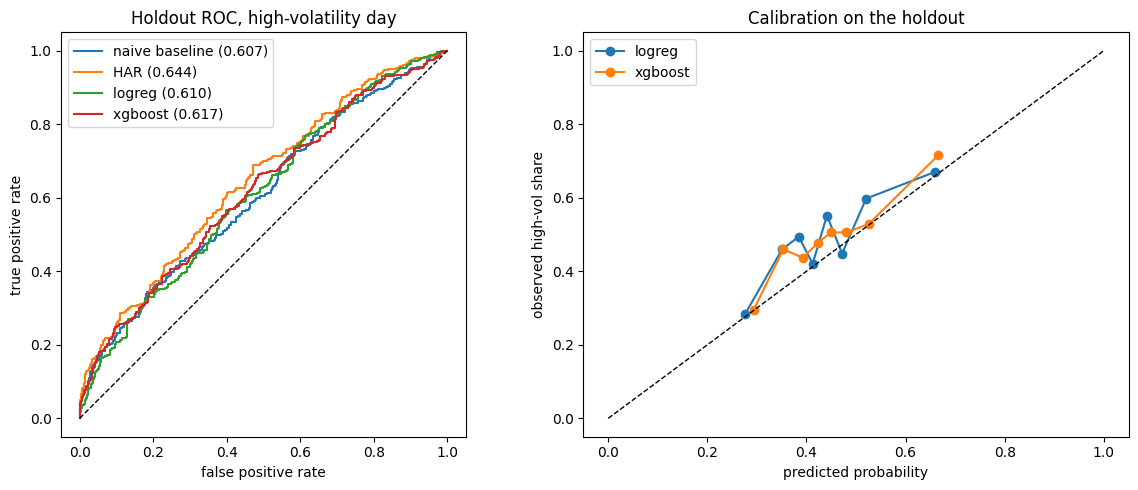

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for name in ["naive baseline", "HAR", "logreg", "xgboost"]:
    s = hold[("volatility", name)]
    fpr, tpr, _ = roc_curve(y_te, s)
    ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_te, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
ax[0].set_aspect("equal")
ax[0].set_xlabel("false positive rate"); ax[0].set_ylabel("true positive rate")
ax[0].set_title("Holdout ROC, high-volatility day")
ax[0].legend()

for name in ["logreg", "xgboost"]:
    frac, mean_p = calibration_curve(y_te, hold[("volatility", name)], n_bins=8, strategy="quantile")
    ax[1].plot(mean_p, frac, marker="o", label=name)
ax[1].plot([0, 1], [0, 1], "k--", lw=1)
ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("observed high-vol share")
ax[1].set_title("Calibration on the holdout")
ax[1].legend()
plt.tight_layout()
plt.show()

In [28]:
# Decision threshold = 80th percentile of out-of-fold predictions on the TRAINING years (not the holdout)
p_te = hold[("volatility", "logreg")]
thr = np.nanquantile(oof_store[("volatility", "logreg")], 0.8)
flag_hi = p_te >= thr
print(f"threshold {thr:.2f} (from training years) flags {flag_hi.mean():.0%} of holdout days; "
      f"{y_te[flag_hi].mean():.0%} of them were high-vol vs {y_te.mean():.0%} overall")

# Economic check: does cutting exposure on flagged days reduce risk of a long-gold position?
next_ret = d["ret"].shift(-1)[ok].iloc[te_pos].to_numpy() / 100
print(f"next-day |return| on flagged days {np.abs(next_ret[flag_hi]).mean() * 100:.2f}% "
      f"vs other days {np.abs(next_ret[~flag_hi]).mean() * 100:.2f}%")

def risk_stats(r):
    eq = np.cumprod(1 + r)
    return {"ann_vol_%": r.std() * np.sqrt(252) * 100, "max_drawdown_%": (eq / np.maximum.accumulate(eq) - 1).min() * 100,
            "return_per_unit_vol": r.mean() / r.std() * np.sqrt(252)}

pd.DataFrame({"always 1x long": risk_stats(next_ret),
              "0.5x on flagged days": risk_stats(np.where(flag_hi, 0.5, 1.0) * next_ret)}).T.round(2)

threshold 0.58 (from training years) flags 10% of holdout days; 71% of them were high-vol vs 49% overall
next-day |return| on flagged days 1.33% vs other days 0.96%


,ann_vol_%,max_drawdown_%,return_per_unit_vol
always 1x long,22.05,-24.94,1.26
0.5x on flagged days,20.05,-27.07,1.29


odds ratio for a 1-standard-deviation increase in each feature (logistic regression, training fit):
range_vs_median    1.44
NFP_tomorrow       1.26
vix                1.14
FOMC_tomorrow      1.14
range_5d_vs_20d    1.13
vix_chg_5d         1.11
CPI_tomorrow       1.04
ry_abs_move        1.00
dxy_abs_move       0.98
vol_5d             0.96
ret_z              0.96
monday_tomorrow    0.90
vol_20d            0.87
abs_ret_z          0.80


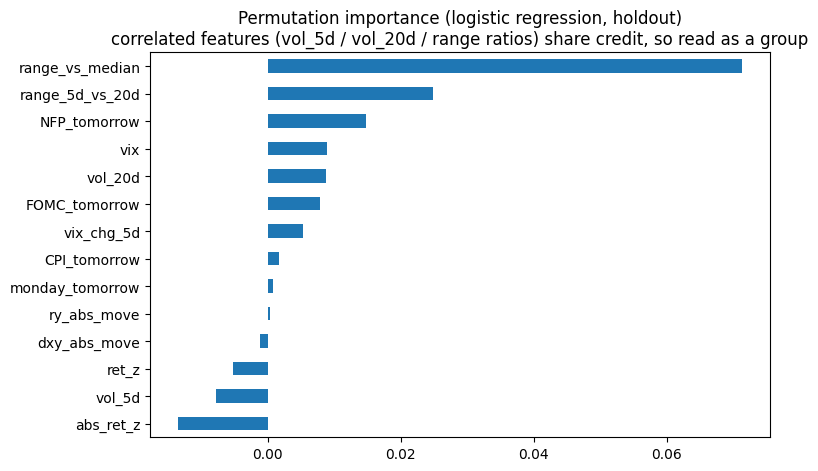

In [29]:
final_lr = make_model("logreg", **best[("volatility", "logreg")]).fit(X_ok.iloc[tr_pos], y_vol[ok].iloc[tr_pos])
coefs = pd.Series(final_lr[-1].coef_[0], index=X_ok.columns)
print("odds ratio for a 1-standard-deviation increase in each feature (logistic regression, training fit):")
print(np.exp(coefs).sort_values(ascending=False).round(2).to_string())

imp = permutation_importance(final_lr, X_ok.iloc[te_pos], y_vol[ok].iloc[te_pos], scoring="roc_auc",
                             n_repeats=15, random_state=SEED)
pd.Series(imp.importances_mean, index=X_ok.columns).sort_values().plot.barh(figsize=(8, 5))
plt.title("Permutation importance (logistic regression, holdout)\n"
          "correlated features (vol_5d / vol_20d / range ratios) share credit, so read as a group")
plt.show()

In [30]:
final = make_model("logreg", **best[("volatility", "logreg")]).fit(X_ok, y_vol[ok])
latest = X.dropna().iloc[[-1]]
print(f"features as of {latest.index[0].date()} -> next session ({next_day.loc[latest.index[0]].date()}): "
      f"{final.predict_proba(latest)[0, 1]:.0%} chance of a high-vol day")

features as of 2026-10-13 -> next session (2026-10-14): 44% chance of a high-vol day


**Findings.** Volatility is partly predictable; direction is not. In my run the logistic regression scored ~0.61 ⟳ AUC both walk-forward and on the 2024-26 holdout, and on the days it was most confident about, ~65% ⟳ were high-vol days vs ~49% normally. XGBoost did not beat the linear model, so the simpler, more explainable model is preferred. The biggest drivers are today's range, the 5-day trend in range, NFP/FOMC tomorrow and the VIX level. Direction models were ~0.50-0.52 ⟳ AUC, a coin flip, and their intervals include 0.5.

**What the corrected evaluation adds.**
- *Versus the baselines:* the original comparison had the naive baseline at 0.607 vs 0.61 on the holdout. The paired-difference table is the real test: if the interval for "logreg vs naive" or "logreg vs HAR" includes zero, the honest claim is that the model **matches** the standard benchmarks, and its value lies in the event-calendar features and in being calibrated, not in raw ranking power.
- *Stability:* the per-fold min/std shows whether 0.61 is consistent or an average of good and bad years.
- *Calibration:* if the reliability curve hugs the diagonal and the Brier score beats the base-rate Brier, the probabilities can be used directly for sizing.
- *Economic value:* the risk table checks the practical claim. Halving exposure on flagged days should lower volatility and drawdown more than it lowers return; if return per unit of volatility improves, the forecast is useful even with a modest AUC.

In practice I'd use it for position sizing: smaller size / wider stops when the model flags a high-vol day, especially before NFP and FOMC.

## Summary for a non-technical audience
- **Timing:** most of gold's daily movement happens in New York hours, especially right after US data at 08:30; London is comparatively quiet once you account for where highs and lows would fall by chance.
- **London breakout:** a popular rule of thumb did not show an edge once realistic fills and gold's uptrend were accounted for.
- **News days:** jobs reports and Fed decisions reliably make gold more volatile; the Fed effect lingers for a day or two.
- **Dollar and real yields:** they still push gold around day to day, but they no longer explain where gold is heading over months and years.
- **Abnormal days:** an anomaly model picks out recognisable market shocks and tells you which factor drove each one.
- **Forecasting:** tomorrow's *volatility* can be forecast modestly well, enough to size positions more safely; tomorrow's *direction* cannot.

## Limitations and next steps
- Hourly analysis covers only ~2 years, all in one market regime; a longer intraday history (paid data) would test whether Sections 1-2 hold in falling markets.
- Futures are a close but imperfect proxy for spot; contract-roll gaps are flagged, not removed.
- Volatility model: next candidates are GARCH-family models and a richer event feature, e.g. scoring the tone of FOMC statements with a language model (hawkish/dovish) as an input. Before any production use it would need monitoring for drift in AUC and calibration.
- Pipeline: the SQLite + cached-CSV design is a proof of concept; the same SQL views would move directly to a cloud warehouse with scheduled ingestion and the data-quality checks from Section 0 as automated tests.